Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB
None


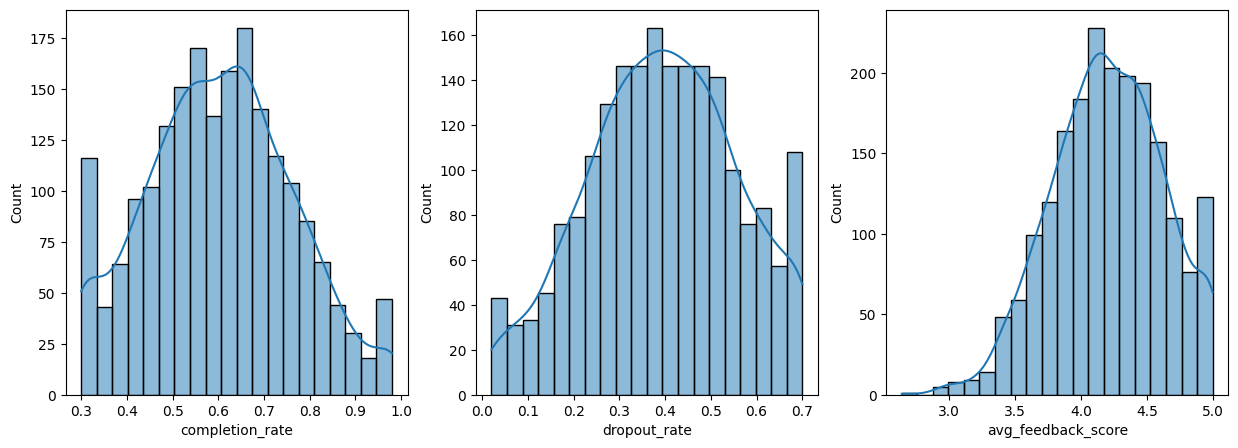

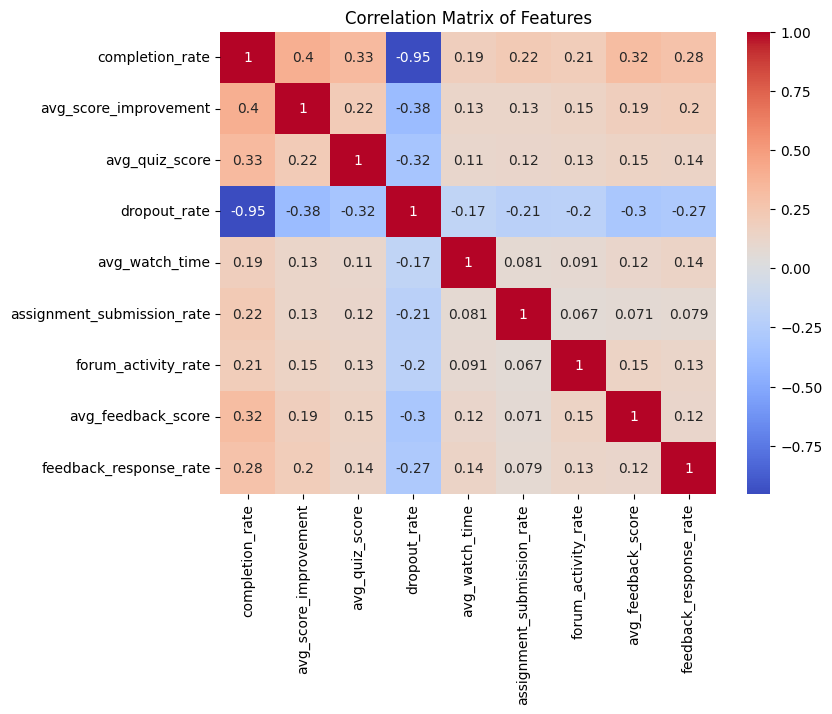

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
# Opening Csv Datafile as Dataframe and Printing Datasetinfo
df = pd.read_csv('instructor_effectiveness_dataset_2000_rows.csv')
print("Dataset Info:")
print(df.info())

#Creating Plot with 1 row and 3 Coloums
fig, axes = plt.subplots(1, 3,figsize=(15, 5)) #Size=15 inch Width and 5 inch Height
sns.histplot(df['completion_rate'], bins=20, kde=True, ax=axes[0])
sns.histplot(df['dropout_rate'], bins=20, kde=True, ax=axes[1])
sns.histplot(df['avg_feedback_score'], bins=20, kde=True, ax=axes[2])
plt.show()

# Correlation Matrix
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix of Features")
plt.show()

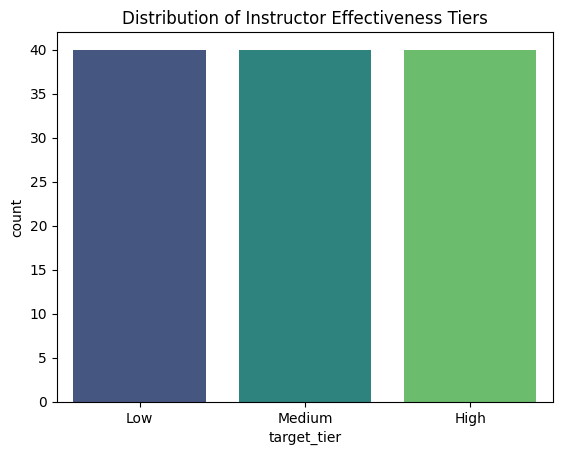

In [29]:
# 1. Batch to the Instructor Level
agg_funcs = {
    'completion_rate': 'mean',
    'avg_score_improvement': 'mean',
    'avg_quiz_score': 'mean',
    'avg_watch_time': 'mean',
    'assignment_submission_rate': 'mean',
    'forum_activity_rate': 'mean',
    'avg_feedback_score': 'mean',
    'feedback_response_rate': 'mean',
    'batch_id': 'count'
}
instructor_df = df.groupby('instructor_id').agg(agg_funcs).reset_index()
instructor_df.rename(columns={'batch_id': 'total_batches_taught'}, inplace=True)

# 2. Engineer the Target Variable
instructor_df['normalized_feedback'] = instructor_df['avg_feedback_score'] / 5.0
student_effort = (instructor_df['avg_watch_time'] + instructor_df['assignment_submission_rate']) / 2

instructor_df['final_score'] = (0.40 * instructor_df['completion_rate']) + (0.30 * student_effort) + (0.30 * instructor_df['normalized_feedback'])
instructor_df['target_tier'] = pd.qcut(instructor_df['final_score'], q=3, labels=['Low', 'Medium', 'High'])

# 3. Verify Tier Balance
sns.countplot(x=instructor_df['target_tier'], hue=instructor_df['target_tier'], palette='viridis', legend=False)
plt.title('Distribution of Instructor Effectiveness Tiers')
plt.show()

In [34]:
# Drop setup columns to prevent data leakage
model_df = instructor_df.drop(columns=['final_score', 'normalized_feedback', 'instructor_id'])

# Separate Features (X) and Target (y)
X = model_df.drop(columns=['target_tier'])
y = model_df['target_tier']

# Train-Test Split (80% Training, 30% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Classification Report:

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        16
         Low       0.85      0.92      0.88        12
      Medium       0.95      0.90      0.92        20

    accuracy                           0.94        48
   macro avg       0.93      0.94      0.93        48
weighted avg       0.94      0.94      0.94        48



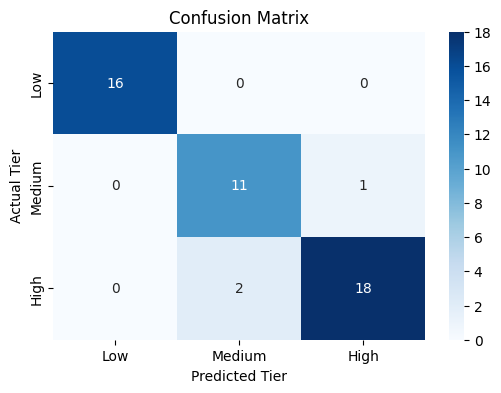

In [33]:
# Train the Random Forest Model
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

# Generate Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Tier')
plt.xlabel('Predicted Tier')
plt.show()

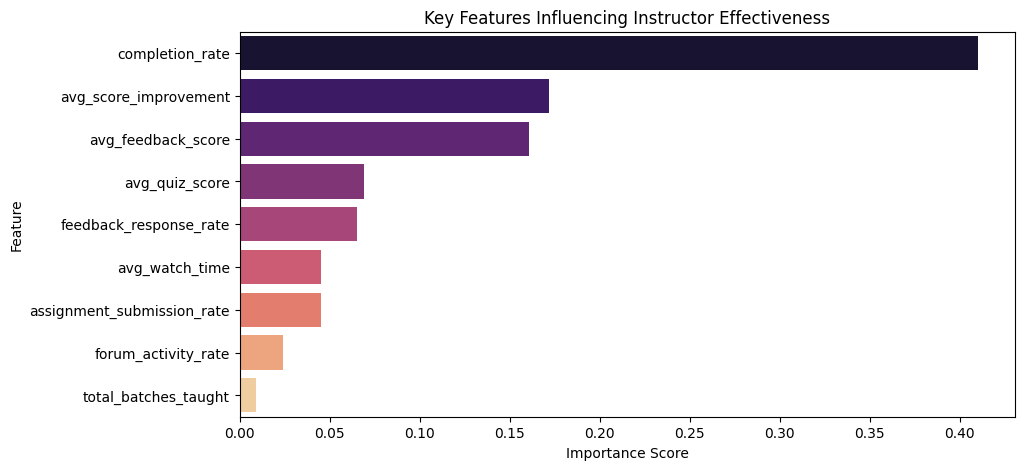

In [28]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='magma', legend=False)
plt.title('Key Features Influencing Instructor Effectiveness')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()